![Python Banner](../../Image/05_07_Policy_Learners.png)


# 7.3 Policy Forest

PyCausalML's `DRPolicyForest` averages many policy trees. Each tree is a weighted classifier on the sign of the doubly robust score. The ensemble is more stable than the single tree in the previous notebook. This is the forest policy used by EconML's policy learner.

## Overview

### What is Policy Forest?

PyCausalML's `DRPolicyForest` is an ensemble of policy trees that:

1. **Learns multiple policy trees** on different bootstrap samples or feature subsets
2. **Aggregates predictions** across trees to reduce variance and improve stability
3. **Provides uncertainty quantification** through bootstrap distributions
4. **Handles complex heterogeneity** better than single trees

### Key Features

- **Ensemble method**: Combines multiple trees for robustness
- **Reduced variance**: Aggregation reduces overfitting and improves generalization
- **Uncertainty quantification**: Bootstrap provides confidence intervals
- **Flexible ML models**: Can use any scikit-learn compatible model
- **Robust policy learning**: More stable than single policy trees
- **Visualization**: Can plot individual trees for interpretation

### Business Setting

Policy Forest is ideal when:

- **Robustness needed**: Single policy trees may overfit
- **Complex heterogeneity**: Treatment effects vary in complex ways
- **Uncertainty quantification**: Need confidence intervals for policy decisions
- **Large datasets**: Sufficient data to support ensemble methods
- **Binary treatment**: Treatment is yes/no

Common business applications:

- Large-scale customer targeting
- Credit scoring with robust policies
- Marketing campaign optimization
- Healthcare treatment allocation

## Setup

Install the required packages:

In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

try:
    import pycausalml  # noqa: F401
    print("PyCausalML ready.")
except ImportError:
    root = _repo_root()
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot]"],
    )
    print("PyCausalML installed.")


PyCausalML ready.


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.tree import plot_tree

from pycausalml import DRPolicyForest, DRPolicyTree
from pycausalml.policy_learners import policy_value

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print("Imported PyCausalML")


def show_policy_tree(model, feature_names, title, tree_index=None):
    """Draw a policy tree. ``tree_index`` selects one tree from a forest."""
    if getattr(model, "policy_", None) is None:
        print(f"{title}: constant policy = {model.constant_}")
        return
    estimator = model.policy_
    if tree_index is not None:
        estimator = estimator.estimators_[tree_index]
    fig, ax = plt.subplots(figsize=(14, 8))
    plot_tree(
        estimator,
        feature_names=list(feature_names),
        class_names=["control", "treat"],
        filled=True,
        rounded=True,
        impurity=False,
        ax=ax,
        fontsize=8,
    )
    ax.set_title(title)
    fig.tight_layout()
    plt.show()


Imported PyCausalML


## Example: Synthetic Policy Learning Data

We'll use the same synthetic data as the DR Policy Tree example:

In [3]:
def create_policy_data(n_samples=1000, n_features=5, random_state=42):
    """
    Create synthetic data for policy learning.
    
    Treatment effect depends on covariates:
    - Positive effect for high values of X1
    - Negative effect for high values of X2
    """
    np.random.seed(random_state)
    
    # Generate covariates
    X = np.random.normal(0, 1, (n_samples, n_features))
    
    # True CATE: heterogeneous treatment effect
    tau = 2 * X[:, 0] - 1.5 * X[:, 1] + 0.5 * X[:, 2]
    
    # Treatment assignment (depends on covariates)
    propensity = 1 / (1 + np.exp(-(0.5 * X[:, 0] + 0.3 * X[:, 1])))
    T = np.random.binomial(1, propensity)
    
    # Outcome
    Y = 10 + np.sum(X[:, :3], axis=1) + tau * T + np.random.normal(0, 1, n_samples)
    
    # Create DataFrame
    feature_names = [f'X{i}' for i in range(n_features)]
    df = pd.DataFrame(X, columns=feature_names)
    df['T'] = T
    df['Y'] = Y
    df['tau_true'] = tau  # true CATE for evaluation
    
    return df

# Generate data
df = create_policy_data(n_samples=1000, n_features=5)
print(df.head())

      X0     X1    X2     X3     X4  T      Y  tau_true
0  0.497 -0.138 0.648  1.523 -0.234  1 12.988     1.525
1 -0.234  1.579 0.767 -0.469  0.543  1 11.757    -2.453
2 -0.463 -0.466 0.242 -1.913 -1.725  0  9.175    -0.107
3 -0.562 -1.013 0.314 -0.908 -1.412  0  9.330     0.552
4  1.466 -0.226 0.068 -1.425 -0.544  1 14.504     3.304


## Step 1: Train Policy Forest

Train a Policy Forest ensemble:

In [4]:
X = df[[f"X{i}" for i in range(5)]]
T = df["T"].to_numpy()
Y = df["Y"].to_numpy()
feature_names = list(X.columns)

policy_forest = DRPolicyForest(
    max_depth=3,
    n_policy_trees=40,
    n_splits=3,
    nuisance="gbr",
    n_estimators=40,
    random_state=42,
)
policy_forest.fit(X, T, Y)
print("Policy forest fitted")
print(f"Training policy value (IPW): {policy_forest.training_policy_value():.3f}")


Policy forest fitted
Training policy value (IPW): 11.506


## Step 2: Predict Policy

Use the ensemble to make treatment decisions:

In [5]:
policy = policy_forest.predict(X)
df["policy"] = policy

print("Policy predictions:")
print(df[["X0", "X1", "X2", "T", "Y", "policy"]].head(10))
print(f"Treatment rate in data: {df['T'].mean():.3f}")
print(f"Policy treatment rate: {df['policy'].mean():.3f}")


Policy predictions:
      X0     X1     X2  T      Y  policy
0  0.497 -0.138  0.648  1 12.988       1
1 -0.234  1.579  0.767  1 11.757       0
2 -0.463 -0.466  0.242  0  9.175       1
3 -0.562 -1.013  0.314  0  9.330       1
4  1.466 -0.226  0.068  1 14.504       1
5  0.111 -1.151  0.376  1 13.414       1
6 -0.602  1.852 -0.013  0  9.490       0
7 -1.221  0.209 -1.960  1  3.388       0
8  0.738  0.171 -0.116  1 10.331       1
9 -0.720 -0.461  1.057  0  7.370       0
Treatment rate in data: 0.516
Policy treatment rate: 0.509


## Step 3: Evaluate Policy Value

Estimate the expected outcome under the learned policy:

In [6]:
learned_value = policy_forest.training_policy_value()
observed_value = policy_value(Y, T, T, policy_forest.e_hat_)
treat_all = policy_value(Y, T, np.ones_like(T), policy_forest.e_hat_)

print(f"Learned policy value (IPW): {learned_value:.3f}")
print(f"Observed assignment value (IPW): {observed_value:.3f}")
print(f"Treat-all value (IPW): {treat_all:.3f}")
print(f"Gain over observed assignment: {learned_value - observed_value:.3f}")


Learned policy value (IPW): 11.506
Observed assignment value (IPW): 20.108
Treat-all value (IPW): 10.201
Gain over observed assignment: -8.602


## Step 4: Compare with Single Policy Tree

Compare the ensemble with a single policy tree:

In [7]:
policy_tree = DRPolicyTree(
    max_depth=3,
    n_splits=3,
    nuisance="gbr",
    n_estimators=40,
    random_state=42,
)
policy_tree.fit(X, T, Y)
tree_value = policy_tree.training_policy_value()

print("Comparison:")
print(f"Single policy tree value: {tree_value:.3f}")
print(f"Policy forest value: {learned_value:.3f}")
print(f"Difference: {learned_value - tree_value:.3f}")


Comparison:
Single policy tree value: 11.168
Policy forest value: 11.506
Difference: 0.338


The ensemble typically provides a more stable and robust policy value estimate.

## Step 5: Visualize Individual Trees

Visualize one of the trees in the ensemble for interpretation:

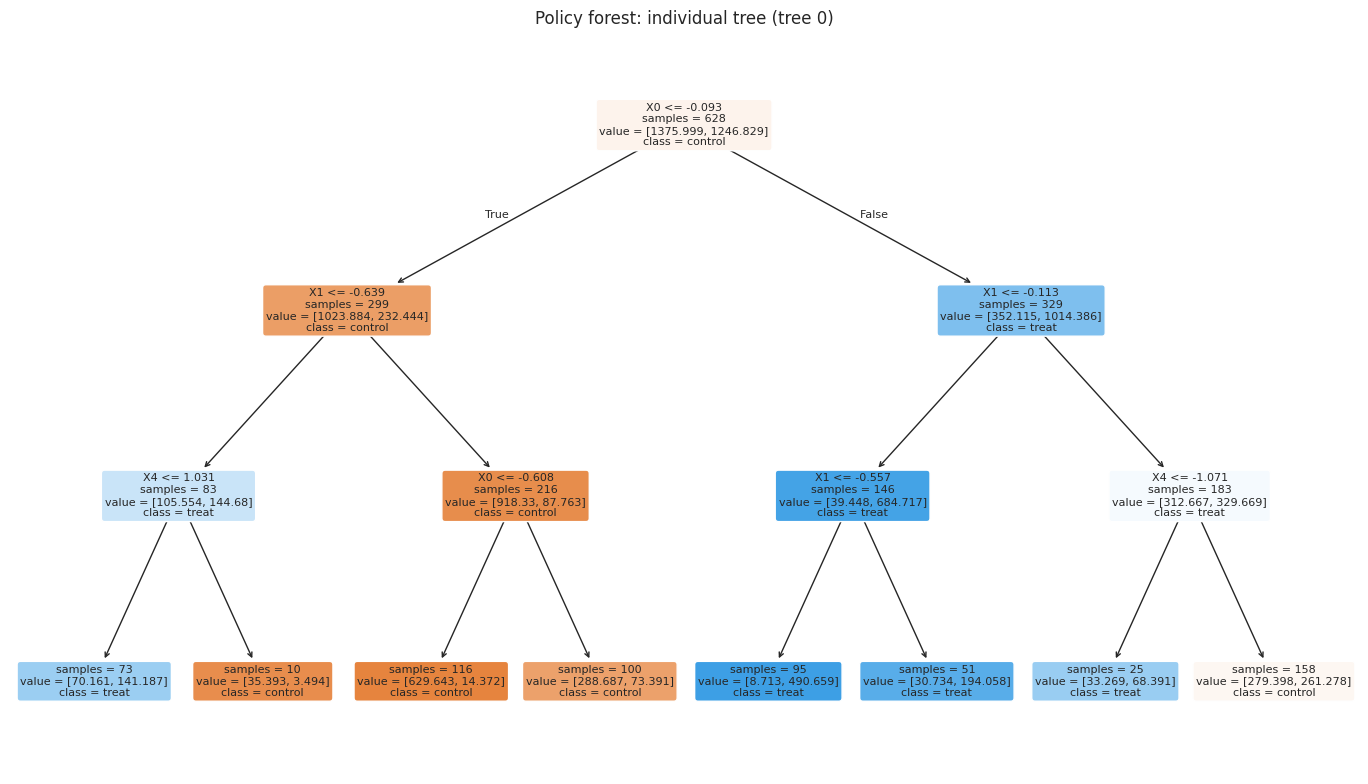

In [8]:
show_policy_tree(
    policy_forest,
    feature_names,
    "Policy forest: individual tree (tree 0)",
    tree_index=0,
)


This shows one of the trees in the ensemble. Different trees may have different splits, but they aggregate to a consistent policy.

## Step 6: Bootstrap Uncertainty

Policy Forest can provide uncertainty estimates through bootstrap:

In [9]:
# Bootstrap the IPW value of the fitted policy (the assignment rule stays fixed).
rng = np.random.default_rng(42)
pi = policy_forest.predict(X)
draws = np.empty(300)
for i in range(len(draws)):
    idx = rng.integers(0, len(Y), len(Y))
    draws[i] = policy_value(Y[idx], T[idx], pi[idx], policy_forest.e_hat_[idx])
lo, hi = np.quantile(draws, [0.05, 0.95])
print(f"Policy value: {draws.mean():.3f}")
print(f"90% bootstrap interval: [{lo:.3f}, {hi:.3f}]")


Policy value: 11.518
90% bootstrap interval: [10.952, 12.136]


## Step 7: Hyperparameter Tuning

Key hyperparameters for Policy Forest:

- **n_policy_trees**: Number of trees in the ensemble (more trees = more robust but slower)
- **max_depth**: Maximum depth of each tree
- **min_samples_leaf**: Minimum samples per leaf
- **min_impurity_decrease**: Minimum impurity decrease for splits
- **max_features**: Features to consider for splits

In [10]:
for n_trees in [20, 40, 80]:
    pf = DRPolicyForest(
        max_depth=3,
        n_policy_trees=n_trees,
        n_splits=2,
        nuisance="gbr",
        n_estimators=25,
        random_state=42,
    )
    pf.fit(X, T, Y)
    print(f"n_policy_trees={n_trees}: policy value = {pf.training_policy_value():.3f}")


n_policy_trees=20: policy value = 11.416


n_policy_trees=40: policy value = 11.525


n_policy_trees=80: policy value = 11.383


## Step 8: Different ML Models

Try different ML models for the outcome and propensity models:

In [11]:
policy_forest_rf = DRPolicyForest(
    max_depth=3,
    n_policy_trees=40,
    n_splits=3,
    nuisance="rf",
    n_estimators=40,
    random_state=42,
)
policy_forest_rf.fit(X, T, Y)
print(f"Policy value with random-forest nuisances: {policy_forest_rf.training_policy_value():.3f}")


Policy value with random-forest nuisances: 11.494


## Common Pitfalls

### 1. Too Few Trees

With too few trees, the ensemble may not reduce variance sufficiently.

**Solution**: Use at least 50-100 trees for reliable variance reduction.

### 2. Overfitting Individual Trees

If individual trees are too deep, they may overfit, and the ensemble may inherit this bias.

**Solution**: Limit tree depth, increase min_samples_leaf, or use stronger regularization.

### 3. Computational Cost

Policy forests can be computationally expensive with many trees and large datasets.

**Solution**: Use fewer trees, limit tree depth, or use subsampling.

## When to Use Policy Forest

Policy Forest is the right choice when:

- **Robustness needed**: Single trees may overfit
- **Complex heterogeneity**: Effects vary in complex ways
- **Uncertainty quantification**: Need confidence intervals
- **Large datasets**: Sufficient data to support ensembles
- **Binary treatment**: Treatment is yes/no

Consider alternatives when:

- Small datasets → Single policy tree or simpler methods
- Interpretability is paramount → Single policy tree
- Computational constraints → Fewer trees or shallower depth
- Multi-armed treatment → Multi-arm policy methods

## Summary

PyCausalML's `DRPolicyForest` is an ensemble policy. Averaging trees reduces variance compared with a single `DRPolicyTree`.

**Key takeaways:**

- Policy Forest is an ensemble of policy trees for robustness
- Aggregation reduces variance and improves generalization
- Provides uncertainty quantification through bootstrap
- Can use any scikit-learn compatible ML models
- Individual trees can be visualized for interpretation
- More trees = more robust but slower
- Balance complexity (depth, trees) with computational cost
- Always validate policies on held-out data
- Consider trade-offs between single trees and forests

## Scientific Terminology

Plain-language definitions for the terms in this tutorial are in the [scientific terminology glossary](../00-scientific-terminology-glossary.qmd).
